# Demo pipeline

**Nota:** En este pipeline se asume que un dataset crudo ya se encuentra subido en HANA

In [1]:
import os
from dotenv import load_dotenv
import hana_ml.dataframe as dataframe
from hana_ml.algorithms.pal.preprocessing import IsolationForest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import time, importlib, ventanas, explicacion

## 1. Lectura del archivo

In [2]:
# Load environment variables from .env file
load_dotenv()

HANA_ADDRESS = os.getenv("HANA_ADDRESS")
HANA_PORT = int(os.getenv("HANA_PORT"))
HANA_USER = os.getenv("HANA_USER")
HANA_PASSWORD = os.getenv("HANA_PASSWORD")

conn = dataframe.ConnectionContext(address = HANA_ADDRESS,
                                   port = HANA_PORT,
                                   user = HANA_USER,
                                   password = HANA_PASSWORD
                                   )
conn.connection.isconnected()

True

In [3]:
dataset = conn.table('LOGS_2026_10')

## 2. Preparación de los datos

In [4]:
cols_drop_llm = ['HTTP_STATUS_CODE', 'SERVICE_ID', 'CLIENT_IP']

cols_drop_system = [
    'LLM_ERROR_MESSAGE', 'LLM_RESPONSE_SIZE_BYTES', 'SAP_LLM_RESPONSE_SIZE',
    'SAP_LLM_RESPONSE_TIME', 'LLM_PROMPT_TOKENS', 'LLM_COMPLETION_TOKENS',
    'LLM_TOTAL_TOKENS', 'LLM_RESPONSE_TIME_MS', 'LLM_MODEL_ID', 'LLM_STATUS',
    'LLM_COST_USD', 'LLM_PROMPT_CATEGORY', 'LLM_TEMPERATURE', 'LLM_TOP_P',
    'LLM_STREAM', 'LLM_FINISH_REASON', 'LLM_PROMPT_ID', 'LLM_PROVIDER', 'LLM_PROMPT',
]

dataset = dataset.drop(['_IGNORED'])

df_llm = dataset.filter("\"_INDEX\" LIKE 'llm-logs%'").drop(cols_drop_llm)
df_system = dataset.filter("\"_INDEX\" LIKE 'sap-logs%'").drop(cols_drop_system)

print(len(df_llm.columns), len(df_system.columns))

40 24


In [5]:
WEEK_DAYS = 7
MIN_LAST_DAYS = 3   # si la última semana trae menos de 3 días, se descarta

TS_EXPR = ("TO_TIMESTAMP(REPLACE(REPLACE(\"TIMESTAMP\",'T',' '),'Z',''), "
           "'YYYY-MM-DD HH24:MI:SS.FF3')")

# t0 y t_max sobre la tabla completa (antes de separar), para que system y llm compartan semanas
r = conn.sql(f'SELECT MIN({TS_EXPR}) AS T0, MAX({TS_EXPR}) AS TMAX FROM LOGS_2026_10').collect()
t0, t_max = pd.to_datetime(r.loc[0, 'T0']), pd.to_datetime(r.loc[0, 'TMAX'])

span = t_max - t0
n_full = span // pd.Timedelta(days=WEEK_DAYS)
rest = span - n_full * pd.Timedelta(days=WEEK_DAYS)
n_weeks = n_full + (1 if rest >= pd.Timedelta(days=MIN_LAST_DAYS) else 0)

t0_sql = t0.strftime('%Y-%m-%d %H:%M:%S')
week_expr = (f"FLOOR(SECONDS_BETWEEN(TO_TIMESTAMP('{t0_sql}','YYYY-MM-DD HH24:MI:SS'), "
             f"{TS_EXPR}) / {WEEK_DAYS * 86400})")

def add_week(df):
    return df.select('*', (week_expr, 'WEEK_IDX'))

df_system = add_week(df_system)
df_llm = add_week(df_llm)

# Un DataFrame perezoso por semana (las filas con WEEK_IDX >= n_weeks quedan fuera)
system_weeks = {w: df_system.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}
llm_weeks = {w: df_llm.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}

print(f't0={t0}  t_max={t_max}  n_weeks={n_weeks}')
print('system:', {w: d.count() for w, d in system_weeks.items()})
print('llm:   ', {w: d.count() for w, d in llm_weeks.items()})

t0=2026-10-01 00:00:00  t_max=2026-10-11 23:59:59  n_weeks=2
system: {0: 1441821, 1: 809290}
llm:    {0: 959153, 1: 538547}


## 3. Generación de ventanas

In [6]:
importlib.reload(ventanas)

def make_windows(w):
    """Ventanas system y LLM de la semana w, como tablas temporales en HANA con WINDOW_INDEX."""
    win_sys = ventanas.materialize(conn, ventanas.build_system_windows(conn, system_weeks[w], df_system), '#WIN_SYSTEM')
    win_llm = ventanas.materialize(conn, ventanas.build_llm_windows(conn, llm_weeks[w]), '#WIN_LLM')
    return win_sys, win_llm

## 4. Isolation Forest

In [7]:
FEATURES_SYSTEM = [
    'TOTAL_REQUESTS', 'REQUEST_RATE_STD', 'INTERVAL_CV',
    'UNIQUE_IPS_COUNT', 'IP_ENTROPY', 'IP_TOP_SHARE',
    'ERROR_RATE_400', 'ERROR_RATE_500', 'NON_200_RATE',
    'RATIO_ERROR', 'RATIO_WARN', 'RATIO_SECURITY', 'RATIO_INFO', 'RATIO_AUDIT',
    'GET_VS_POST_RATIO',
    'JS_HTTP_STATUS_CODE', 'JS_HEADERS_HTTP_REQUEST_METHOD', 'JS_SAP_FUNCTION_LOG_TYPE',
    'JS_HEATHERS_REQUEST_PATH', 'JS_SAP_FUNCTION_APPLICATION', 'JS_SAP_SOURCE_TYPE',
    'JS_SAP_APP_ENV', 'JS_REGION_CODE', 'JS_HEADERS_CONTENT_TYPE',
]
FEATURES_LLM = [
    'TOTAL_LLM_REQUESTS', 'AVG_LLM_COST_USD', 'INJECTION_COUNT', 'SAFETY_POLICY_COUNT', 'AUTH_FAILURE_COUNT', 'ACCESS_DENIED_COUNT', 'RATE_ABUSE_COUNT', 'DUPLICATE_REQUEST_COUNT', 'MALFORMED_INPUT_COUNT', 
    'AVG_TOKEN_RATIO', 'AVG_RESPONSE_TIME_MS', 'LLM_ERROR_RATE', 'LLM_TIMEOUT_RATE', 'TEMPERATURE_VARIANCE',
    'PROMPT_CATEGORY_ENTROPY', 'STREAM_RATIO', 'AVG_PROMPT_LENGTH', 'MAX_PROMPT_LENGTH',
]

importlib.reload(explicacion)

def run_if(win, features):
    model = IsolationForest(n_estimators=250, max_samples=256, random_state=42)
    model.fit(data=win, key='WINDOW_INDEX', features=features)
    pred = model.predict(data=win, key='WINDOW_INDEX', features=features,
                         contamination=0.01, show_explainer=False)
    win_pdf = win.collect()
    r = win_pdf.merge(pred.collect(), on='WINDOW_INDEX')              # ventana + SCORE + LABEL

    an = r[r['LABEL'] == -1]
    idx = an['WINDOW_INDEX'].tolist()
    cf = explicacion.contrafactual(conn, model, win, features,
                                   an.set_index('WINDOW_INDEX')['SCORE'], idx)
    z = explicacion.zscores(win_pdf, idx, features)
    return r, cf, z

res = {s: {'r': [], 'cf': [], 'z': []} for s in ('system', 'llm')}
for w in range(n_weeks):
    win_sys, win_llm = make_windows(w)
    for stream, win, feats in (('system', win_sys, FEATURES_SYSTEM), ('llm', win_llm, FEATURES_LLM)):
        r, cf, z = run_if(win, feats)
        for df, name in ((r, 'r'), (cf, 'cf'), (z, 'z')):
            df.insert(0, 'WEEK', w)
            res[stream][name].append(df)

if_system, cf_system, z_system = (pd.concat(res['system'][k], ignore_index=True) for k in ('r', 'cf', 'z'))
if_llm, cf_llm, z_llm = (pd.concat(res['llm'][k], ignore_index=True) for k in ('r', 'cf', 'z'))

In [8]:
MAX_GAP = {'system': 3, 'llm': 3}   # en ventanas consecutivas, como en tu baseline

def agrupar_eventos(res, max_gap):
    """Marca EVENTO_ID: anomalías separadas por <= max_gap ventanas forman un evento. No cruza semanas."""
    res = res.sort_values(['WEEK', 'WINDOW_INDEX']).reset_index(drop=True)
    a = res[res['LABEL'] == -1]
    gap = a.groupby('WEEK')['WINDOW_INDEX'].diff()
    res['EVENTO_ID'] = pd.NA
    res.loc[a.index, 'EVENTO_ID'] = ((gap.isna()) | (gap > max_gap)).cumsum()
    return res

def resumen_eventos(res):
    """Una fila por evento: inicio, fin, nº de ventanas y ventana pico (mayor SCORE de anomalía)."""
    a = res[res['LABEL'] == -1]
    if a.empty:
        return pd.DataFrame()
    # En PAL el score más alto suele ser más anómalo; se confirma comparando medias.
    alto_es_anomalo = a['SCORE'].mean() >= res.loc[res['LABEL'] != -1, 'SCORE'].mean()
    pick = a.groupby('EVENTO_ID')['SCORE'].idxmax() if alto_es_anomalo else a.groupby('EVENTO_ID')['SCORE'].idxmin()
    pico = (a.loc[pick, ['EVENTO_ID', 'WEEK', 'WINDOW_START', 'SCORE']]
            .rename(columns={'WINDOW_START': 'VENTANA_PICO', 'SCORE': 'SCORE_PICO'})
            .set_index('EVENTO_ID'))
    g = a.groupby('EVENTO_ID').agg(INICIO=('WINDOW_START', 'min'), FIN=('WINDOW_START', 'max'),
                                   N_VENTANAS=('WINDOW_INDEX', 'size'))
    return g.join(pico).reset_index()

if_system = agrupar_eventos(if_system, MAX_GAP['system'])
if_llm = agrupar_eventos(if_llm, MAX_GAP['llm'])
eventos_system = resumen_eventos(if_system)
eventos_llm = resumen_eventos(if_llm)

print('System: anomalías =', (if_system['LABEL'] == -1).sum(), '| eventos =', len(eventos_system))
print('LLM:    anomalías =', (if_llm['LABEL'] == -1).sum(), '| eventos =', len(eventos_llm))
display(eventos_system); display(eventos_llm)

System: anomalías = 65 | eventos = 14
LLM:    anomalías = 65 | eventos = 60


,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO
0,1,2026-10-01 05:02:30,2026-10-01 05:02:30,1,0,2026-10-01 05:02:30,0.514522
1,2,2026-10-01 07:57:30,2026-10-01 07:57:30,1,0,2026-10-01 07:57:30,0.551963
2,3,2026-10-01 09:30:00,2026-10-01 09:40:00,5,0,2026-10-01 09:32:30,0.771173
3,4,2026-10-01 12:42:30,2026-10-01 12:57:30,7,0,2026-10-01 12:47:30,0.801721
4,5,2026-10-01 18:30:00,2026-10-01 18:30:00,1,0,2026-10-01 18:30:00,0.516298
5,6,2026-10-01 23:47:30,2026-10-02 00:05:00,8,0,2026-10-01 23:57:30,0.708653
6,7,2026-10-04 10:20:00,2026-10-04 10:22:30,2,0,2026-10-04 10:22:30,0.536519
7,8,2026-10-04 13:50:00,2026-10-04 13:50:00,1,0,2026-10-04 13:50:00,0.521531
8,9,2026-10-05 13:02:30,2026-10-05 13:35:00,14,0,2026-10-05 13:07:30,0.804477
9,10,2026-10-05 23:17:30,2026-10-05 23:17:30,1,0,2026-10-05 23:17:30,0.512919


,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO
0,1,2026-10-01 05:52:30,2026-10-01 05:52:30,1,0,2026-10-01 05:52:30,0.528209
1,2,2026-10-01 06:57:30,2026-10-01 06:57:30,1,0,2026-10-01 06:57:30,0.524271
2,3,2026-10-01 17:00:00,2026-10-01 17:00:00,1,0,2026-10-01 17:00:00,0.525648
3,4,2026-10-01 22:37:30,2026-10-01 22:37:30,1,0,2026-10-01 22:37:30,0.530339
4,5,2026-10-02 02:35:00,2026-10-02 02:35:00,1,0,2026-10-02 02:35:00,0.523195
5,6,2026-10-02 08:00:00,2026-10-02 08:00:00,1,0,2026-10-02 08:00:00,0.535647
6,7,2026-10-02 10:52:30,2026-10-02 10:52:30,1,0,2026-10-02 10:52:30,0.525642
7,8,2026-10-02 14:52:30,2026-10-02 14:52:30,1,0,2026-10-02 14:52:30,0.528255
8,9,2026-10-02 18:47:30,2026-10-02 18:47:30,1,0,2026-10-02 18:47:30,0.531812
9,10,2026-10-02 19:22:30,2026-10-02 19:22:30,1,0,2026-10-02 19:22:30,0.528441


In [9]:
# Por ventana: feature dominante (contrafactual y z-score) junto a cada resultado
if_system = if_system.merge(explicacion.dominantes_por_ventana(cf_system, z_system),
                            on=['WEEK', 'WINDOW_INDEX'], how='left')
if_llm = if_llm.merge(explicacion.dominantes_por_ventana(cf_llm, z_llm),
                      on=['WEEK', 'WINDOW_INDEX'], how='left')

# Por evento: se añade a las tablas de eventos de la celda 2
eventos_system = eventos_system.merge(explicacion.explicar_eventos(if_system, cf_system, z_system),
                                      on='EVENTO_ID', how='left')
eventos_llm = eventos_llm.merge(explicacion.explicar_eventos(if_llm, cf_llm, z_llm),
                                on='EVENTO_ID', how='left')

display(eventos_system); display(eventos_llm)

,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO,CF_FEATURE,CF_DELTA_MEDIO,CF_TOP3,Z_FEATURE,Z_VALOR_MEDIO
0,1,2026-10-01 05:02:30,2026-10-01 05:02:30,1,0,2026-10-01 05:02:30,0.514522,JS_SAP_APP_ENV,0.043213,"JS_SAP_APP_ENV (0.043), JS_HEATHERS_REQUEST_PA...",JS_SAP_APP_ENV,2.448693
1,2,2026-10-01 07:57:30,2026-10-01 07:57:30,1,0,2026-10-01 07:57:30,0.551963,JS_SAP_SOURCE_TYPE,0.026144,"JS_SAP_SOURCE_TYPE (0.026), INTERVAL_CV (0.017...",JS_SAP_SOURCE_TYPE,3.175626
2,3,2026-10-01 09:30:00,2026-10-01 09:40:00,5,0,2026-10-01 09:32:30,0.771173,JS_SAP_FUNCTION_APPLICATION,0.019841,"JS_SAP_FUNCTION_APPLICATION (0.020), JS_HEATHE...",JS_SAP_FUNCTION_APPLICATION,8.630218
3,4,2026-10-01 12:42:30,2026-10-01 12:57:30,7,0,2026-10-01 12:47:30,0.801721,JS_SAP_SOURCE_TYPE,0.017959,"JS_SAP_SOURCE_TYPE (0.018), JS_HEATHERS_REQUES...",JS_SAP_FUNCTION_LOG_TYPE,14.456196
4,5,2026-10-01 18:30:00,2026-10-01 18:30:00,1,0,2026-10-01 18:30:00,0.516298,TOTAL_REQUESTS,0.021673,"TOTAL_REQUESTS (0.022), GET_VS_POST_RATIO (0.0...",ERROR_RATE_400,2.446287
5,6,2026-10-01 23:47:30,2026-10-02 00:05:00,8,0,2026-10-01 23:57:30,0.708653,JS_SAP_FUNCTION_APPLICATION,0.030949,"JS_SAP_FUNCTION_APPLICATION (0.031), JS_SAP_FU...",UNIQUE_IPS_COUNT,21.559249
6,7,2026-10-04 10:20:00,2026-10-04 10:22:30,2,0,2026-10-04 10:22:30,0.536519,REQUEST_RATE_STD,0.023343,"REQUEST_RATE_STD (0.023), RATIO_AUDIT (0.023),...",REQUEST_RATE_STD,3.216411
7,8,2026-10-04 13:50:00,2026-10-04 13:50:00,1,0,2026-10-04 13:50:00,0.521531,REQUEST_RATE_STD,0.035738,"REQUEST_RATE_STD (0.036), JS_SAP_FUNCTION_APPL...",REQUEST_RATE_STD,3.894264
8,9,2026-10-05 13:02:30,2026-10-05 13:35:00,14,0,2026-10-05 13:07:30,0.804477,IP_TOP_SHARE,0.025100,"IP_TOP_SHARE (0.025), JS_SAP_SOURCE_TYPE (0.02...",IP_TOP_SHARE,12.429534
9,10,2026-10-05 23:17:30,2026-10-05 23:17:30,1,0,2026-10-05 23:17:30,0.512919,JS_HEADERS_CONTENT_TYPE,0.028602,"JS_HEADERS_CONTENT_TYPE (0.029), RATIO_ERROR (...",JS_HEADERS_CONTENT_TYPE,5.759838


,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO,CF_FEATURE,CF_DELTA_MEDIO,CF_TOP3,Z_FEATURE,Z_VALOR_MEDIO
0,1,2026-10-01 05:52:30,2026-10-01 05:52:30,1,0,2026-10-01 05:52:30,0.528209,DUPLICATE_REQUEST_COUNT,0.054829,"DUPLICATE_REQUEST_COUNT (0.055), TOTAL_LLM_REQ...",DUPLICATE_REQUEST_COUNT,4.351844
1,2,2026-10-01 06:57:30,2026-10-01 06:57:30,1,0,2026-10-01 06:57:30,0.524271,DUPLICATE_REQUEST_COUNT,0.020994,"DUPLICATE_REQUEST_COUNT (0.021), AVG_TOKEN_RAT...",DUPLICATE_REQUEST_COUNT,2.248957
2,3,2026-10-01 17:00:00,2026-10-01 17:00:00,1,0,2026-10-01 17:00:00,0.525648,DUPLICATE_REQUEST_COUNT,0.030611,"DUPLICATE_REQUEST_COUNT (0.031), AVG_TOKEN_RAT...",AVG_TOKEN_RATIO,-2.590757
3,4,2026-10-01 22:37:30,2026-10-01 22:37:30,1,0,2026-10-01 22:37:30,0.530339,SAFETY_POLICY_COUNT,0.025747,"SAFETY_POLICY_COUNT (0.026), INJECTION_COUNT (...",LLM_ERROR_RATE,2.789849
4,5,2026-10-02 02:35:00,2026-10-02 02:35:00,1,0,2026-10-02 02:35:00,0.523195,INJECTION_COUNT,0.050391,"INJECTION_COUNT (0.050), AVG_TOKEN_RATIO (0.02...",INJECTION_COUNT,4.341821
5,6,2026-10-02 08:00:00,2026-10-02 08:00:00,1,0,2026-10-02 08:00:00,0.535647,DUPLICATE_REQUEST_COUNT,0.044467,"DUPLICATE_REQUEST_COUNT (0.044), ACCESS_DENIED...",DUPLICATE_REQUEST_COUNT,3.300401
6,7,2026-10-02 10:52:30,2026-10-02 10:52:30,1,0,2026-10-02 10:52:30,0.525642,AVG_RESPONSE_TIME_MS,0.043965,"AVG_RESPONSE_TIME_MS (0.044), MALFORMED_INPUT_...",LLM_TIMEOUT_RATE,3.428711
7,8,2026-10-02 14:52:30,2026-10-02 14:52:30,1,0,2026-10-02 14:52:30,0.528255,INJECTION_COUNT,0.029454,"INJECTION_COUNT (0.029), SAFETY_POLICY_COUNT (...",INJECTION_COUNT,3.292107
8,9,2026-10-02 18:47:30,2026-10-02 18:47:30,1,0,2026-10-02 18:47:30,0.531812,MALFORMED_INPUT_COUNT,0.032651,"MALFORMED_INPUT_COUNT (0.033), TEMPERATURE_VAR...",MALFORMED_INPUT_COUNT,3.673437
9,10,2026-10-02 19:22:30,2026-10-02 19:22:30,1,0,2026-10-02 19:22:30,0.528441,DUPLICATE_REQUEST_COUNT,0.025944,"DUPLICATE_REQUEST_COUNT (0.026), INJECTION_COU...",INJECTION_COUNT,3.292107


In [13]:
Z_UMBRAL = 5   # |z| máximo (feature, ventana) que debe alcanzar un evento para considerarse relevante

def marcar_relevantes(if_df, z, eventos, umbral=Z_UMBRAL):
    """Añade a la tabla de eventos Z_MAX, Z_MAX_FEATURE y RELEVANTE (Z_MAX >= umbral)."""
    zz = z.merge(if_df.loc[if_df['LABEL'] == -1, ['WEEK', 'WINDOW_INDEX', 'EVENTO_ID']],
                 on=['WEEK', 'WINDOW_INDEX'])
    zz['ZABS'] = zz['Z'].abs()
    pico = zz.loc[zz.groupby('EVENTO_ID')['ZABS'].idxmax(), ['EVENTO_ID', 'FEATURE', 'ZABS']]
    pico = pico.rename(columns={'FEATURE': 'Z_MAX_FEATURE', 'ZABS': 'Z_MAX'})
    out = eventos.drop(columns=['Z_MAX', 'Z_MAX_FEATURE', 'RELEVANTE'], errors='ignore') \
                 .merge(pico, on='EVENTO_ID', how='left')
    out['RELEVANTE'] = out['Z_MAX'] >= umbral
    return out

eventos_system = marcar_relevantes(if_system, z_system, eventos_system)
eventos_llm = marcar_relevantes(if_llm, z_llm, eventos_llm)

cols = ['EVENTO_ID', 'WEEK', 'INICIO', 'N_VENTANAS', 'SCORE_PICO', 'Z_MAX', 'Z_MAX_FEATURE', 'RELEVANTE']
for nombre, ev in (('System', eventos_system), ('LLM', eventos_llm)):
    print(f'{nombre}: {ev["RELEVANTE"].sum()} relevantes de {len(ev)} eventos (umbral |z| >= {Z_UMBRAL})')
    display(ev.sort_values('Z_MAX', ascending=False)[cols].head(15))


# Dataset para el clustering multiclase: ventanas anómalas de eventos relevantes,
# solo con las columnas de la ventana (sin SCORE, LABEL, EVENTO_ID ni explicaciones).
POST_IF = {'SCORE', 'LABEL', 'EVENTO_ID', 'WINDOW_INDEX'}

def dataset_multiclase(if_df, eventos):
    post = POST_IF | {c for c in if_df.columns if c.startswith(('CF_', 'Z_'))}
    rel = eventos.loc[eventos['RELEVANTE'], 'EVENTO_ID']
    a = if_df[(if_df['LABEL'] == -1) & if_df['EVENTO_ID'].isin(rel)]
    ds = a[[c for c in if_df.columns if c not in post]].reset_index(drop=True)
    mapa = a[['WEEK', 'WINDOW_START', 'EVENTO_ID']].reset_index(drop=True)   # para volver al evento
    return ds, mapa

ds_multi_system, mapa_multi_system = dataset_multiclase(if_system, eventos_system)
ds_multi_llm, mapa_multi_llm = dataset_multiclase(if_llm, eventos_llm)

print('System:', ds_multi_system.shape, '| LLM:', ds_multi_llm.shape)
print(list(ds_multi_system.columns))

System: 8 relevantes de 14 eventos (umbral |z| >= 5)


,EVENTO_ID,WEEK,INICIO,N_VENTANAS,SCORE_PICO,Z_MAX,Z_MAX_FEATURE,RELEVANTE
12,13,1,2026-10-10 02:40:00,6,0.804415,26.562422,JS_HEADERS_HTTP_REQUEST_METHOD,True
3,4,0,2026-10-01 12:42:30,7,0.801721,25.163175,JS_SAP_FUNCTION_APPLICATION,True
5,6,0,2026-10-01 23:47:30,8,0.708653,24.767299,UNIQUE_IPS_COUNT,True
8,9,0,2026-10-05 13:02:30,14,0.804477,21.792049,JS_SAP_SOURCE_TYPE,True
10,11,1,2026-10-09 09:17:30,8,0.656800,15.941580,UNIQUE_IPS_COUNT,True
2,3,0,2026-10-01 09:30:00,5,0.771173,13.373361,JS_SAP_FUNCTION_APPLICATION,True
11,12,1,2026-10-09 10:00:00,9,0.617499,10.121822,UNIQUE_IPS_COUNT,True
9,10,0,2026-10-05 23:17:30,1,0.512919,5.759838,JS_HEADERS_CONTENT_TYPE,True
7,8,0,2026-10-04 13:50:00,1,0.521531,3.894264,REQUEST_RATE_STD,False
6,7,0,2026-10-04 10:20:00,2,0.536519,3.349757,RATIO_AUDIT,False


LLM: 0 relevantes de 60 eventos (umbral |z| >= 5)


,EVENTO_ID,WEEK,INICIO,N_VENTANAS,SCORE_PICO,Z_MAX,Z_MAX_FEATURE,RELEVANTE
52,53,1,2026-10-10 05:25:00,1,0.566847,4.912129,SAFETY_POLICY_COUNT,False
0,1,0,2026-10-01 05:52:30,1,0.528209,4.351844,DUPLICATE_REQUEST_COUNT,False
27,28,0,2026-10-06 02:47:30,2,0.539050,4.351844,DUPLICATE_REQUEST_COUNT,False
24,25,0,2026-10-05 07:00:00,1,0.540213,4.351844,DUPLICATE_REQUEST_COUNT,False
22,23,0,2026-10-04 21:47:30,2,0.526210,4.351844,DUPLICATE_REQUEST_COUNT,False
17,18,0,2026-10-03 20:12:30,1,0.523265,4.351844,DUPLICATE_REQUEST_COUNT,False
15,16,0,2026-10-03 13:50:00,1,0.522688,4.341821,INJECTION_COUNT,False
4,5,0,2026-10-02 02:35:00,1,0.523195,4.341821,INJECTION_COUNT,False
14,15,0,2026-10-03 12:27:30,1,0.531110,4.341821,INJECTION_COUNT,False
49,50,1,2026-10-09 20:57:30,1,0.525165,4.074474,AVG_TOKEN_RATIO,False


System: (58, 29) | LLM: (0, 20)
['WEEK', 'WINDOW_START', 'TOTAL_REQUESTS', 'REQUEST_RATE_STD', 'UNIQUE_IPS_COUNT', 'ERROR_RATE_400', 'ERROR_RATE_500', 'RATIO_ERROR', 'RATIO_WARN', 'RATIO_SECURITY', 'RATIO_INFO', 'RATIO_AUDIT', 'IP_ENTROPY', 'GET_VS_POST_RATIO', 'JS_HTTP_STATUS_CODE', 'JS_HEADERS_HTTP_REQUEST_METHOD', 'JS_SAP_FUNCTION_LOG_TYPE', 'JS_HEATHERS_REQUEST_PATH', 'JS_SAP_FUNCTION_APPLICATION', 'JS_SAP_SOURCE_TYPE', 'JS_SAP_APP_ENV', 'JS_REGION_CODE', 'JS_HEADERS_HTTP_HOST', 'JS_HEADERS_CONTENT_TYPE', 'IP_TOP_SHARE', 'NOVEL_IPS', 'NOVEL_PATHS', 'NON_200_RATE', 'INTERVAL_CV']


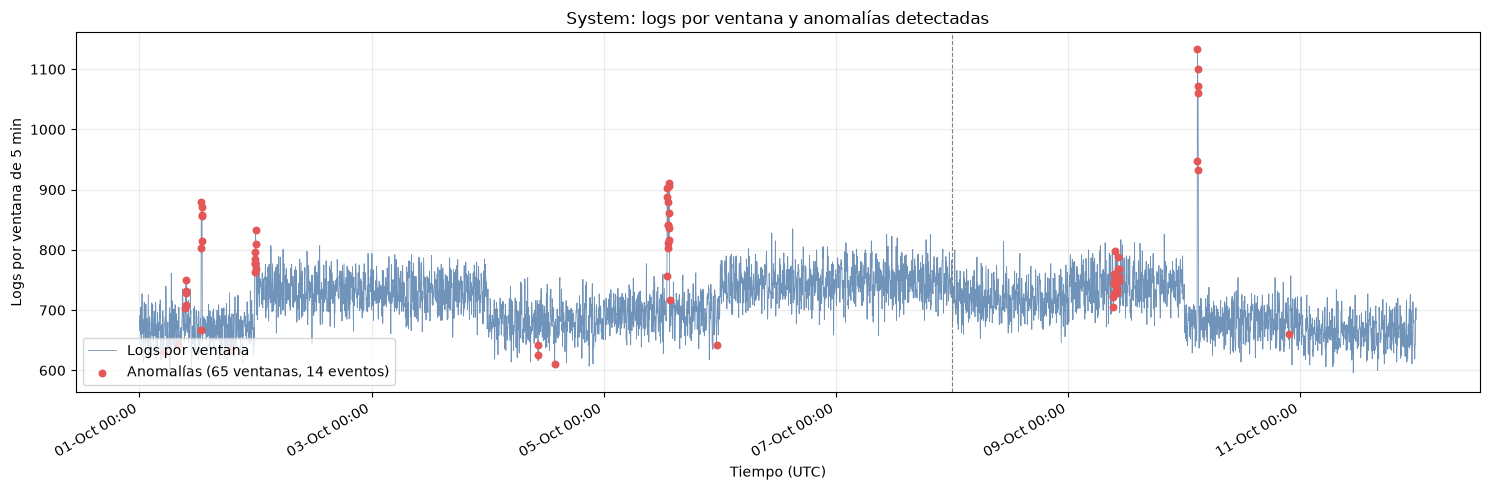

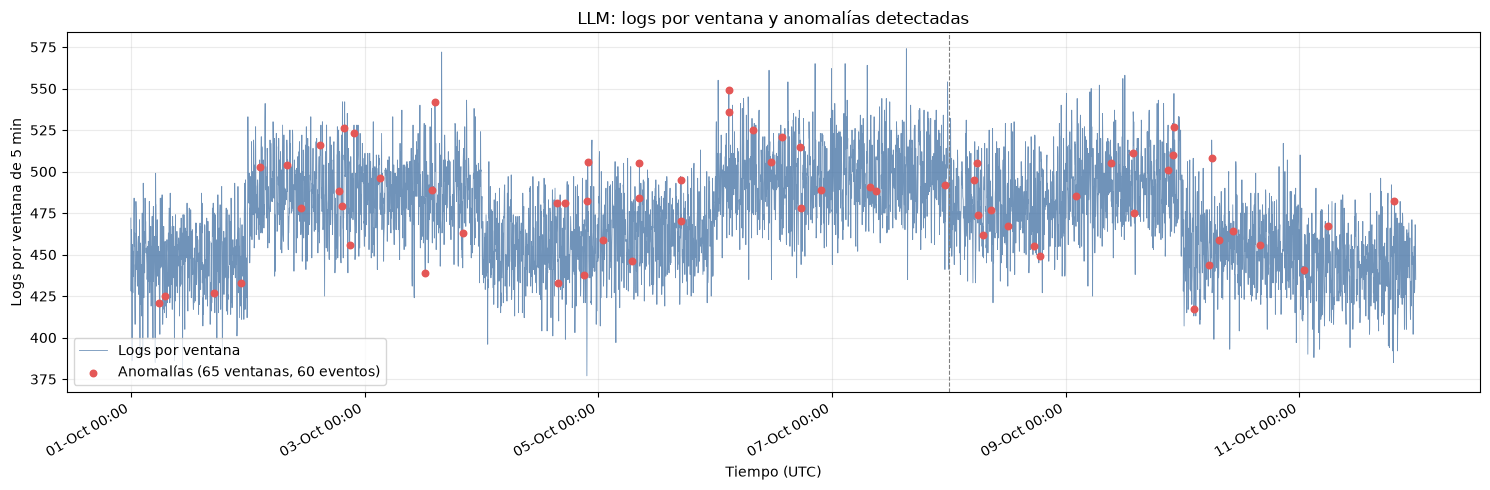

In [10]:
def graficar(res, col, titulo):
    d = res.sort_values('WINDOW_START')
    a = d[d['LABEL'] == -1]
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(d['WINDOW_START'], d[col], color='#4c78a8', lw=0.6, alpha=0.8, label='Logs por ventana')
    ax.scatter(a['WINDOW_START'], a[col], color='#e45756', s=22, zorder=3,
               label=f"Anomalías ({len(a)} ventanas, {a['EVENTO_ID'].nunique()} eventos)")
    for w, g in d.groupby('WEEK'):
        if w > 0:
            ax.axvline(g['WINDOW_START'].min(), color='gray', ls='--', lw=0.8)   # corte de semana
    ax.set_title(titulo)
    ax.set_xlabel('Tiempo (UTC)')
    ax.set_ylabel('Logs por ventana de 5 min')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %H:%M'))
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

graficar(if_system, 'TOTAL_REQUESTS', 'System: logs por ventana y anomalías detectadas')
graficar(if_llm, 'TOTAL_LLM_REQUESTS', 'LLM: logs por ventana y anomalías detectadas')

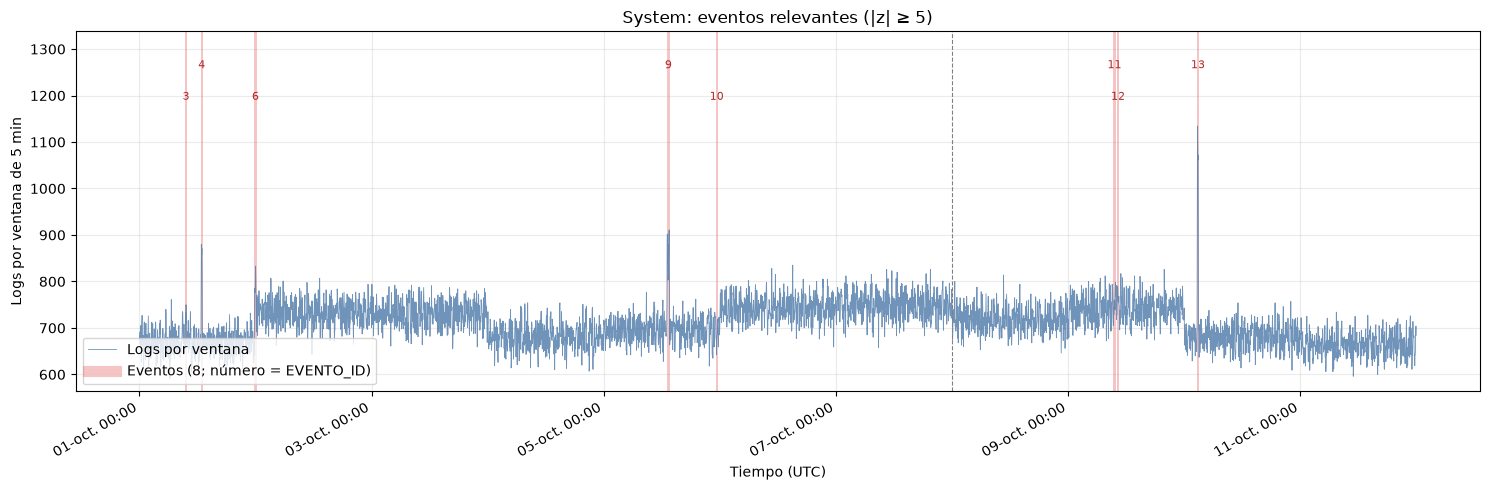

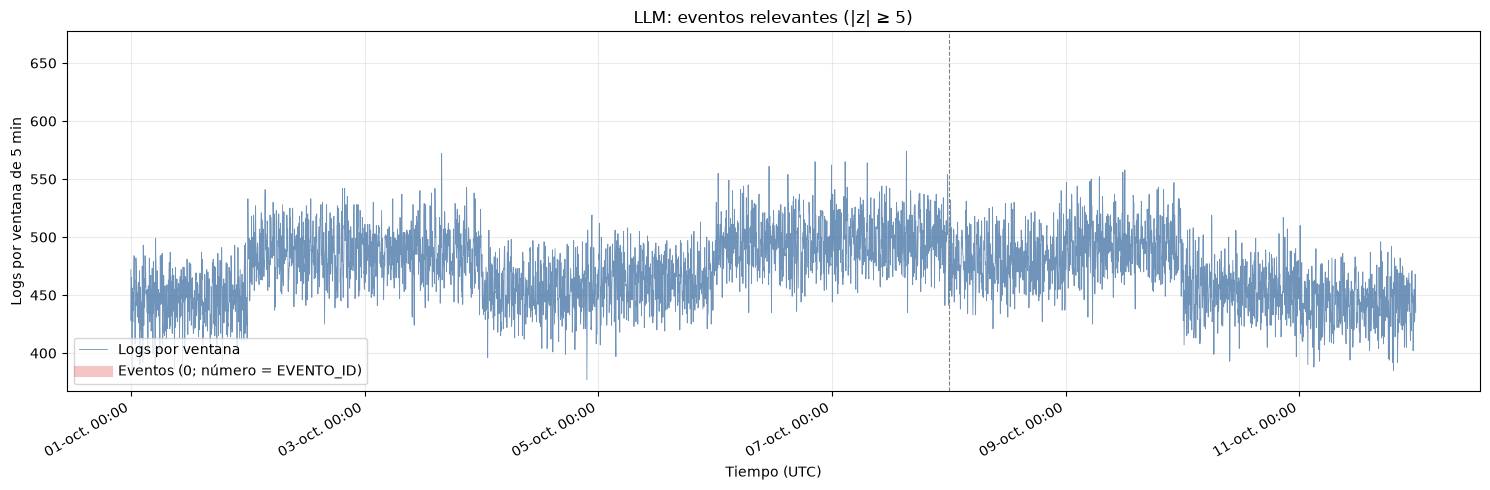

In [15]:
def graficar_eventos(res, eventos, col, titulo, solo_relevantes=True, ancho_min_min=30):
    d = res.sort_values('WINDOW_START')
    ev = eventos[eventos['RELEVANTE']] if solo_relevantes else eventos
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(d['WINDOW_START'], d[col], color='#4c78a8', lw=0.6, alpha=0.8, label='Logs por ventana')
    for w, g in d.groupby('WEEK'):
        if w > 0:
            ax.axvline(g['WINDOW_START'].min(), color='gray', ls='--', lw=0.8)   # corte de semana

    ymax = d[col].max()
    ax.set_ylim(top=ymax * 1.18)
    for k, e in enumerate(ev.sort_values('INICIO').itertuples()):
        ini = e.INICIO
        fin = e.FIN + pd.Timedelta(minutes=5)                      # una ventana dura 5 min
        mid = ini + (fin - ini) / 2
        piso = pd.Timedelta(minutes=ancho_min_min)                 # ancho mínimo para que se vea
        if fin - ini < piso:
            ini, fin = mid - piso / 2, mid + piso / 2
        ax.axvspan(ini, fin, color='#e45756', alpha=0.35, lw=0)
        ax.text(mid, ymax * (1.05 if k % 2 == 0 else 1.11), str(e.EVENTO_ID),
                ha='center', fontsize=8, color='#b02a2a')          # alterna alturas para no encimar
    ax.plot([], [], color='#e45756', alpha=0.35, lw=8,
            label=f'Eventos ({len(ev)}; número = EVENTO_ID)')

    ax.set_title(titulo)
    ax.set_xlabel('Tiempo (UTC)')
    ax.set_ylabel('Logs por ventana de 5 min')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %H:%M'))
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

graficar_eventos(if_system, eventos_system, 'TOTAL_REQUESTS',
                 f'System: eventos relevantes (|z| ≥ {Z_UMBRAL})')
graficar_eventos(if_llm, eventos_llm, 'TOTAL_LLM_REQUESTS',
                 f'LLM: eventos relevantes (|z| ≥ {Z_UMBRAL})')

,EVENTO_ID,WEEK,INICIO,FIN,N_VENTANAS,SCORE_PICO,Z_MAX,Volumen y ritmo,Origen (IPs),Tipo de log,Respuestas HTTP,Peticiones,Contexto SAP,TOP_FEATURES
7,13,1,2026-10-10 02:40:00,2026-10-10 02:52:30,6,0.804415,26.562422,5.31,12.43,7.71,10.22,11.99,13.30,"IP_TOP_SHARE (+18.9), JS_HTTP_STATUS_CODE (+18.3), JS_SAP_APP_ENV (+18.0)"
1,4,0,2026-10-01 12:42:30,2026-10-01 12:57:30,7,0.801721,25.163175,1.96,7.31,5.59,5.71,5.97,10.14,"JS_SAP_FUNCTION_LOG_TYPE (+14.5), JS_SAP_FUNCTION_APPLICATION (+14.4), JS_HEATHERS_REQ..."
2,6,0,2026-10-01 23:47:30,2026-10-02 00:05:00,8,0.708653,24.767299,1.44,8.74,2.03,2.40,0.81,3.95,"UNIQUE_IPS_COUNT (+21.6), JS_SAP_FUNCTION_APPLICATION (+5.9), ERROR_RATE_500 (+4.3)"
3,9,0,2026-10-05 13:02:30,2026-10-05 13:35:00,14,0.804477,21.792049,2.10,8.03,3.95,6.36,7.59,8.20,"IP_TOP_SHARE (+12.4), JS_HTTP_STATUS_CODE (+11.6), JS_SAP_APP_ENV (+11.5)"
5,11,1,2026-10-09 09:17:30,2026-10-09 09:45:00,8,0.656800,15.941580,0.91,3.77,0.88,0.83,0.96,0.77,"UNIQUE_IPS_COUNT (+9.7), JS_HEATHERS_REQUEST_PATH (+1.8), ERROR_RATE_400 (+1.7)"
0,3,0,2026-10-01 09:30:00,2026-10-01 09:40:00,5,0.771173,13.373361,0.54,4.93,2.52,4.33,4.02,6.26,"JS_SAP_FUNCTION_APPLICATION (+8.6), IP_TOP_SHARE (+8.0), JS_HTTP_STATUS_CODE (+7.5)"
6,12,1,2026-10-09 10:00:00,2026-10-09 10:30:00,9,0.617499,10.121822,1.18,3.17,0.85,0.66,0.89,0.42,"UNIQUE_IPS_COUNT (+8.1), REQUEST_RATE_STD (-1.5), JS_HEATHERS_REQUEST_PATH (+1.3)"
4,10,0,2026-10-05 23:17:30,2026-10-05 23:17:30,1,0.512919,5.759838,1.55,0.25,0.93,1.06,1.63,0.48,"JS_HEADERS_CONTENT_TYPE (+5.8), ERROR_RATE_500 (-2.3), REQUEST_RATE_STD (+2.3)"


,EVENTO_ID,WEEK,INICIO,FIN,N_VENTANAS,SCORE_PICO,Z_MAX,Volumen y recursos,Fallos,Contenido del prompt,Parámetros de la llamada,Mensajes de seguridad,TOP_FEATURES


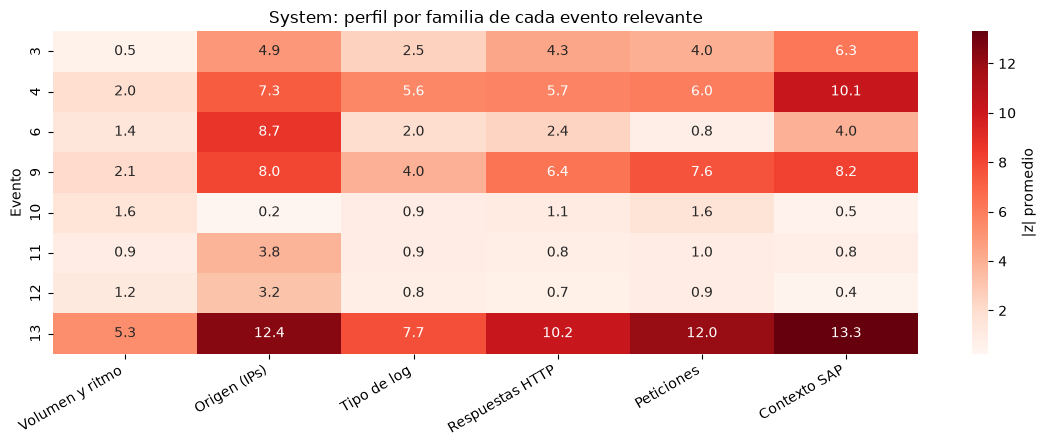

LLM: sin eventos relevantes, no hay mapa de calor.


In [16]:
importlib.reload(explicacion)

base_cols = ['EVENTO_ID', 'WEEK', 'INICIO', 'FIN', 'N_VENTANAS', 'SCORE_PICO', 'Z_MAX']

def perfil_relevantes(eventos, if_df, z, familias):
    """Perfil por familia solo de los eventos relevantes (RELEVANTE = True)."""
    rel = eventos[eventos['RELEVANTE']]
    return rel[base_cols].merge(explicacion.perfil_familias(if_df, z, familias), on='EVENTO_ID')

perfil_system = perfil_relevantes(eventos_system, if_system, z_system, explicacion.FAMILIAS_SYSTEM)
perfil_llm = perfil_relevantes(eventos_llm, if_llm, z_llm, explicacion.FAMILIAS_LLM)

with pd.option_context('display.width', 250, 'display.max_columns', None, 'display.max_colwidth', 90):
    display(perfil_system.sort_values('Z_MAX', ascending=False))
    display(perfil_llm.sort_values('Z_MAX', ascending=False))

# Mapa de calor: una fila por evento relevante, una columna por familia (|z| promedio)
for nombre, perfil, familias in (('System', perfil_system, explicacion.FAMILIAS_SYSTEM),
                                 ('LLM', perfil_llm, explicacion.FAMILIAS_LLM)):
    if perfil.empty:
        print(f'{nombre}: sin eventos relevantes, no hay mapa de calor.')
        continue
    mapa = perfil.set_index('EVENTO_ID')[list(familias)]
    fig, ax = plt.subplots(figsize=(1.6 * len(familias) + 2, 0.32 * len(mapa) + 2))
    sns.heatmap(mapa, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': '|z| promedio'}, ax=ax)
    ax.set_title(f'{nombre}: perfil por familia de cada evento relevante')
    ax.set_ylabel('Evento')
    ax.set_xlabel('')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

In [17]:
CLIP_Z = None   # p. ej. 10 para recortar colas largas; None = sin recorte

def normalizar_por_semana(ds, if_df, features, clip=None):
    """
    Z-score con signo de las `features` de las ventanas de `ds`, con media y desviación de TODAS
    las ventanas de su semana (if_df), no solo de las anómalas. Devuelve solo esas variables,
    en el mismo orden de filas que `ds`. sd = 0 o valor faltante -> z = 0.
    """
    g = if_df.groupby('WEEK')[features]
    mu = g.mean()
    sd = g.std(ddof=0).replace(0, np.nan)
    sem = ds['WEEK'].values
    z = (ds[features].astype(float).values - mu.loc[sem].values) / sd.loc[sem].values
    z = pd.DataFrame(z, columns=features).fillna(0)
    return z.clip(-clip, clip) if clip else z

X_multi_system = normalizar_por_semana(ds_multi_system, if_system, FEATURES_SYSTEM, CLIP_Z)
X_multi_llm = normalizar_por_semana(ds_multi_llm, if_llm, FEATURES_LLM, CLIP_Z)

for nombre, X, ds, mapa, feats in (
        ('System', X_multi_system, ds_multi_system, mapa_multi_system, FEATURES_SYSTEM),
        ('LLM', X_multi_llm, ds_multi_llm, mapa_multi_llm, FEATURES_LLM)):
    assert len(X) == len(ds) == len(mapa), f'{nombre}: filas desalineadas'
    assert list(X.columns) == feats, f'{nombre}: columnas distintas a las del IF'
    assert not X.isna().any().any(), f'{nombre}: hay NaN'
    print(f'{nombre}: X = {X.shape} | eventos = {mapa["EVENTO_ID"].nunique()} | '
          f'|z| máx = {X.abs().max().max():.1f}')

System: X = (58, 24) | eventos = 8 | |z| máx = 26.6
LLM: X = (0, 18) | eventos = 0 | |z| máx = nan


## 5. Separación Multi-Clase

## 6. Clustering Multi-Clase

## 7. Validación Clustering Vs. Separación